In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
category_tree_path = r'../EDA-RS datasets\RetailRocket dataset\category_tree.csv'
eventes_path = r'../EDA-RS datasets\RetailRocket dataset\events.csv'
item_prop1_path = r'../EDA-RS datasets\RetailRocket dataset\item_properties_part1.csv'
item_prop2_path = r'../EDA-RS datasets\RetailRocket dataset\item_properties_part2.csv'

category_tree = pd.read_csv(category_tree_path)
events = pd.read_csv(eventes_path)
item_prop1 = pd.read_csv(item_prop1_path)
item_prop2 = pd.read_csv(item_prop2_path)

In [4]:
category_tree.head()

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


In [41]:
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [4]:
item_props = pd.concat([item_prop1, item_prop2])
item_props.head()

,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513


In [6]:
print(f"Shape of category tree: {category_tree.shape}")
print(f"Shape of events: {events.shape}")
print(f"Shape of item properties: {item_props.shape}")

Shape of category tree: (1669, 2)
Shape of events: (2756101, 5)
Shape of item properties: (20275902, 4)


In [7]:
print(f"Missing values of events : {events.isnull().sum()}")
print(f"Missing values of categories tree : {category_tree.isnull().sum()}")
print(f"Missing values of item props : {item_props.isnull().sum()}")

Missing values of events : timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64
Missing values of categories tree : categoryid     0
parentid      25
dtype: int64
Missing values of item props : timestamp    0
itemid       0
property     0
value        0
dtype: int64


In [6]:
event_types = events['event'].unique()
event_types

array(['view', 'addtocart', 'transaction'], dtype=object)

In [7]:
events.dropna(subset=['itemid', 'visitorid'], inplace=True)

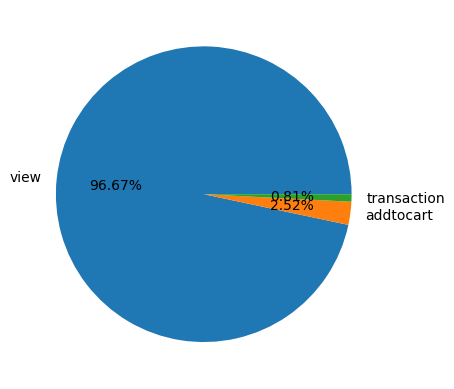

In [144]:
ax = plt.pie(x=events['event'].value_counts(), labels=event_types,autopct='%1.2f%%')
plt.show()

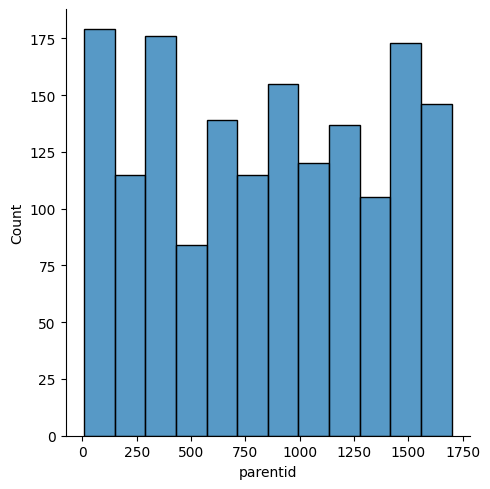

In [10]:
sns.displot(category_tree,x = 'parentid')
plt.show()

In [38]:
events['timestamp'] = pd.to_datetime(events['timestamp'], unit='ms')
item_props['timestamp'] = pd.to_datetime(item_props['timestamp'], unit='ms')
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,2015-06-02 05:02:12.117,257597,view,355908,NaN
1,2015-06-02 05:50:14.164,992329,view,248676,NaN
2,2015-06-02 05:13:19.827,111016,view,318965,NaN
3,2015-06-02 05:12:35.914,483717,view,253185,NaN
4,2015-06-02 05:02:17.106,951259,view,367447,NaN


In [ ]:
basket_per_visitor = events[events['event'] == 'transaction'].groupby(['visitorid', 'timestamp'])['itemid'].agg(['count']).sort_values(by='transactionid',ascending=True).reset_index()
basket_per_visitor[basket_per_visitor['visitorid'] == 1297062].sort_values(by='timestamp', ascending=False)

,visitorid,transactionid,timestamp,count
5082,1297062,4417.0,2015-08-03 23:27:48.159,1
17264,1297062,14951.0,2015-08-03 23:00:57.140,1
15917,1297062,13772.0,2015-08-03 21:51:53.721,1
15227,1297062,13172.0,2015-08-03 21:35:37.426,1
2488,1297062,2152.0,2015-08-03 20:39:03.179,1
...,...,...,...,...
17363,1297062,15037.0,2015-07-03 23:07:42.527,1
4337,1297062,3768.0,2015-07-03 20:35:58.988,1
16773,1297062,14523.0,2015-07-03 19:38:04.812,2
18160,1297062,15733.0,2015-07-03 18:32:48.175,1


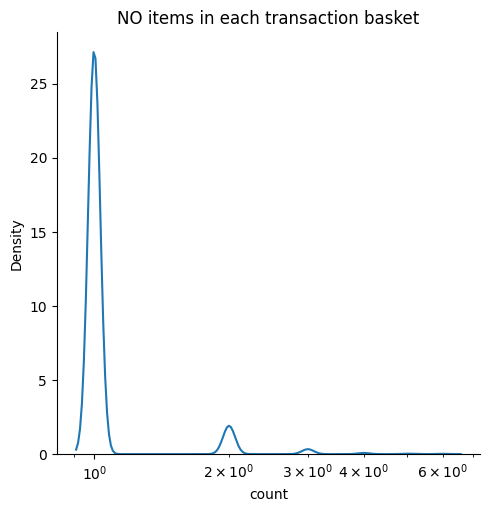

In [14]:
facet = sns.displot(data=basket_per_visitor,x='count',kind='kde',log_scale=True)
facet.ax.set_title('NO items in each transaction basket')
plt.show()

In [ ]:
sub = events.drop_duplicates(subset=['itemid','event'],keep='last')
sub.pivot(index='itemid',columns='event',values='timestamp')

In [ ]:
#Density of items in view, add to cart or transaction events
visitor_items = events.groupby('visitorid')['itemid'].count().rename('count').reset_index()
sns.displot(data=visitor_items,x='count',kind='kde',log_scale=True)
plt.show()

In [ ]:
# How many users just browse, add to cart or really bought something?
visitor_event_group = events.groupby(['visitorid','event'])['itemid'].count().rename('itemcount').reset_index()
viewer_visitors = visitor_event_group[visitor_event_group['event'] == 'view']
addToCart_visitors = visitor_event_group[visitor_event_group['event'] == 'addtocart']
transaction_visitors = visitor_event_group[visitor_event_group['event'] == 'transaction']

#Users that view and do something else(add to cart, transaction)
view_addtocart_transaction = viewer_visitors.merge(addToCart_visitors.merge(transaction_visitors, on='visitorid',how='inner'),on='visitorid',how='inner')
view_addtocart = viewer_visitors.merge(addToCart_visitors,on='visitorid',how='inner')

,visitorid,event_x,itemcount_x,event_y,itemcount_y
0,6,view,5,addtocart,1
1,150,view,3,addtocart,1
2,155,view,7,addtocart,7
3,172,view,33,addtocart,3
4,177,view,2,addtocart,1
...,...,...,...,...,...
34396,1407129,view,3,addtocart,1
34397,1407355,view,1,addtocart,1
34398,1407430,view,5,addtocart,1
34399,1407437,view,5,addtocart,1


In [47]:
#Users that only do view
only_view_temp = viewer_visitors.merge(visitor_event_group[visitor_event_group['event'].isin(['transaction','addtocart'])],on='visitorid',how='left',indicator=True)
only_view = only_view_temp[only_view_temp['_merge'] == 'left_only']
#Users that only do add to cart
only_addtocart_temp = addToCart_visitors.merge(visitor_event_group[visitor_event_group['event'].isin(['view','transaction'])],on='visitorid',how='left',indicator=True)
only_addtocart = only_addtocart_temp[only_addtocart_temp['_merge'] == 'left_only']
#Users that only do transaction
only_transaction_temp = transaction_visitors.merge(visitor_event_group[visitor_event_group['event'].isin(['view','addtocart'])],on='visitorid',how='left',indicator=True)
only_transaction = only_transaction_temp[only_transaction_temp['_merge'] == 'left_only']

In [55]:
event_analysis = [only_view.shape[0],only_addtocart.shape[0],only_transaction.shape[0],view_addtocart_transaction.shape[0],view_addtocart.shape[0]]
event_analysis_types = ['only_view','only_addtocart','only_transaction','view & addtocart & transaction','view & addtocart']

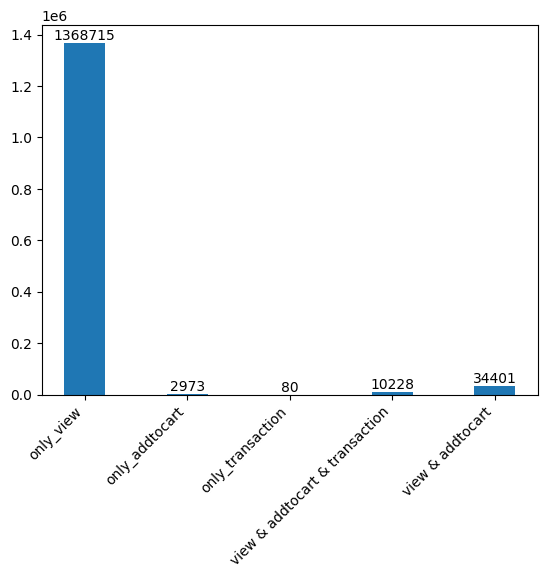

In [ ]:
ax = plt.bar(event_analysis_types,event_analysis,width=0.4)

#Written by CHATGPT
for bar in ax:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(height),
        ha='center',
        va='bottom',
        fontsize=10
    )
plt.xticks(rotation=45, ha='right')  # 'ha' aligns the text neatly at the bar base
plt.show()

<Axes: title={'center': 'Transactions per Hour of the Day'}, xlabel='timestamp'>

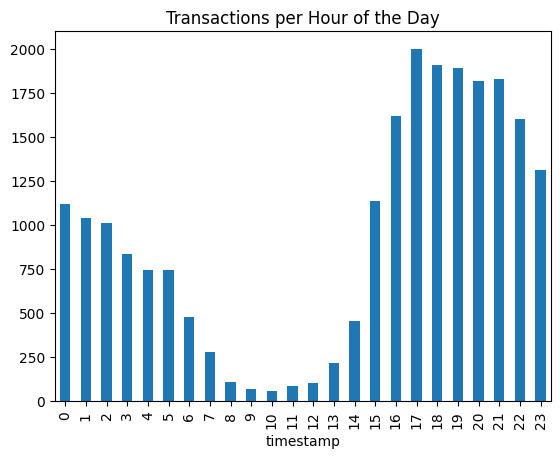

In [9]:
#Is there any relationship between View Time and Transaction?
df = events[['timestamp','transactionid']]
df[df['transactionid'].notnull()].groupby(df['timestamp'].dt.hour)['transactionid'].count().plot(kind='bar',title='Transactions per Hour of the Day')

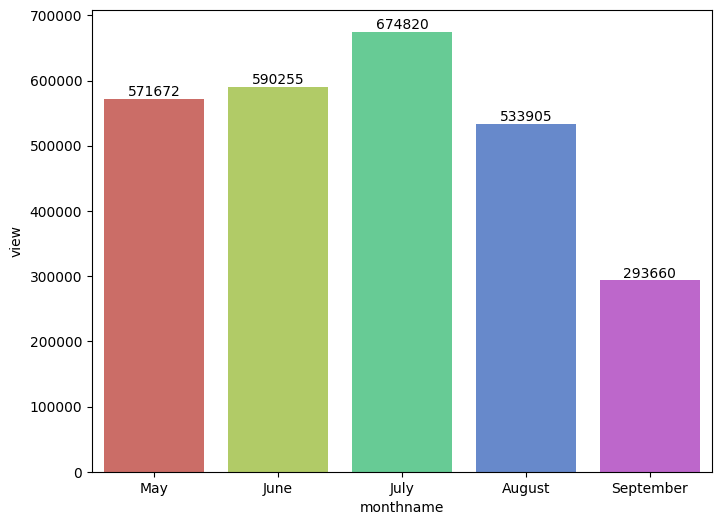

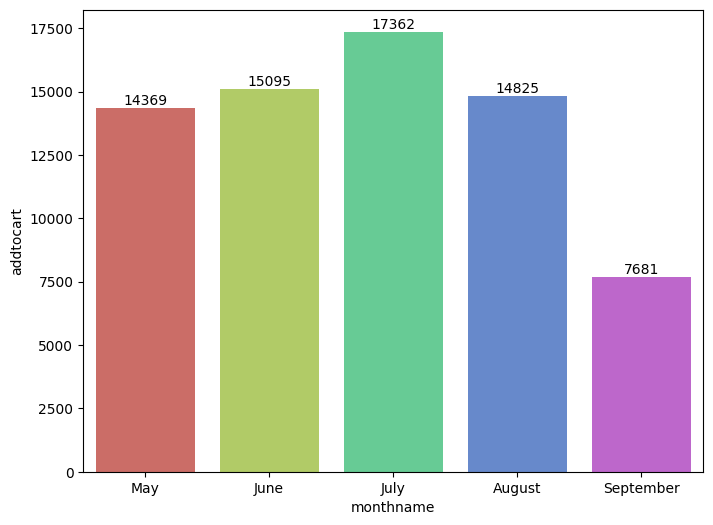

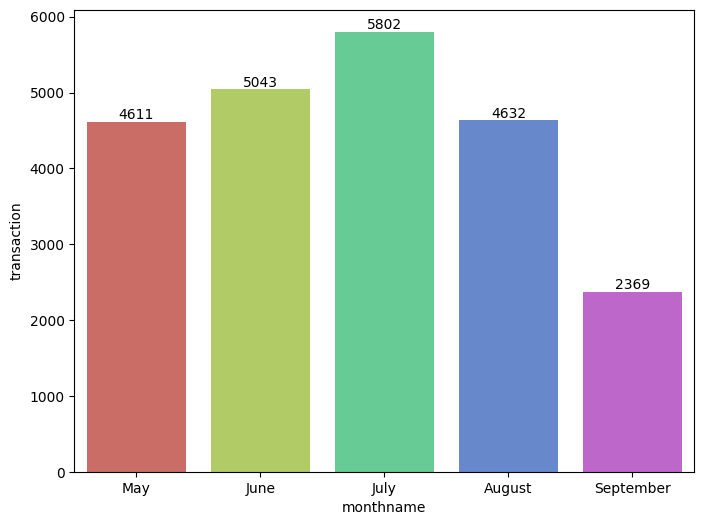

In [140]:
df3 = events[['timestamp','event']].copy()
df3['monthname'] = df3['timestamp'].dt.month_name()
df3['month'] = df3['timestamp'].dt.month

history_dict = dict()
for e in event_types:
    plt.figure(figsize=(8, 6))
    event_type = df3[df3['event'] == e]
    result = pd.DataFrame(event_type.groupby(['monthname','month'])['event'].count().reset_index()).sort_values('month')
    history_dict[e] = result
    ax = sns.barplot(result,x='monthname',y='event',palette=sns.color_palette('hls',5),hue='monthname')
    ax.set_ylabel(e)
    for container in ax.containers:
        ax.bar_label(container)
    plt.show()

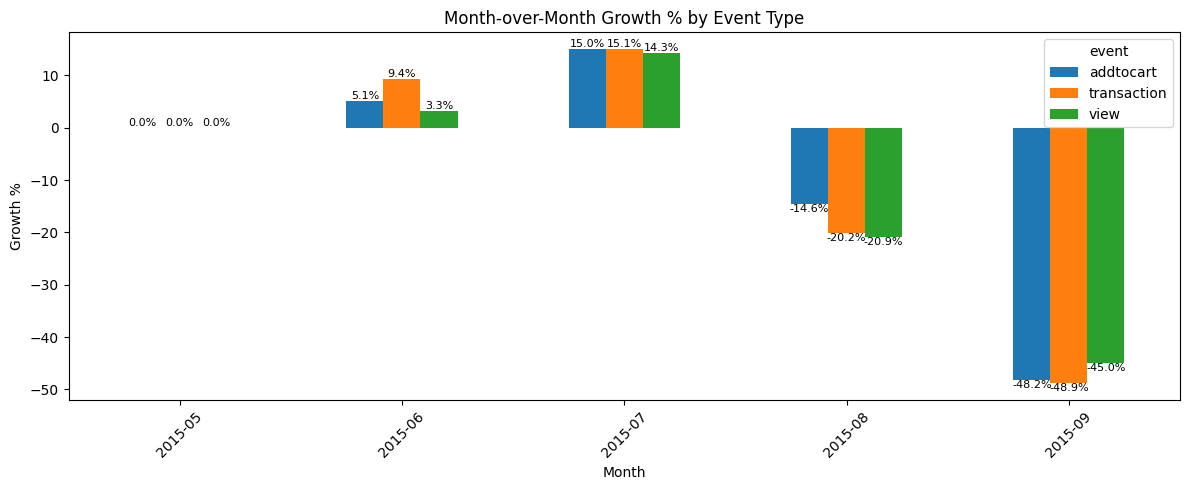

In [141]:
# Monthly count of each event type
df2 = events[['timestamp', 'event']].copy()
df2['month'] = df2['timestamp'].dt.to_period('M')
monthly = df2.groupby(['month', 'event']).size().unstack(fill_value=0)

# Month-over-month growth percentage
growth = monthly.pct_change() * 100

ax = growth.plot(kind='bar', figsize=(12, 5), title='Month-over-Month Growth % by Event Type')
plt.ylabel('Growth %')
plt.xlabel('Month')
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
top_5_props = item_props.groupby(['property']).size().sort_values(ascending=False).iloc[:5].reset_index()
top_5 = top_5_props['property']
top_5

0           888
1           790
2     available
3    categoryid
4             6
Name: property, dtype: object

In [6]:
from scipy.stats import chi2_contingency

compact_events = events.groupby(['event','itemid']).size().reset_index(name='Occurance_count')
compact_cat = item_props.loc[item_props['property'].eq('categoryid'), ['itemid', 'value']]
compact_cat = compact_cat.drop_duplicates(['itemid','value'])
merged =compact_events.merge(compact_cat,how='inner',on='itemid')
#Claude -------------
ct = pd.pivot_table(
    merged,
    index='event',
    columns='value',                # categoryid
    values='Occurance_count',
    aggfunc='sum',
    fill_value=0
)
#----------------

In [ ]:
#Claude
chi2, p ,dof, expected = chi2_contingency(ct.values)
n = ct.values.sum()
r, k = ct.shape
cramers_v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))

print(f"Cramer's V: {cramers_v:.4f}, p-value: {p:.5e}")

Cramer's V: 0.0839, p-value: 0.00000e+00


In [ ]:
top_cats = merged.groupby(['value'])['Occurance_count'].sum().sort_values(ascending=False).head(100).index
m2 = merged[merged['value'].isin(top_cats)]

pivot = m2.pivot_table(
    index=['itemid','value'],
    columns = 'event',
    values = 'Occurance_count',
    fill_value = 0
).reset_index()
#Turn each value to one-hot encoded lilke
pivot_cat = pd.get_dummies(pivot['value'], prefix='cat')
event_cols = [c for c in pivot.columns if c not in ['itemid', 'value']]
X_event = pivot[event_cols]
correlation = pd.concat([pivot_cat, X_event], axis=1).corr()
print(correlation['addtocart'].sort_values(ascending=False).head(10))
print(correlation['view'].sort_values(ascending=False).head(10))
print(correlation['transaction'].sort_values(ascending=False).head(10))

In [ ]:
#Calculate conversion(view-addtocart) for each product for custom intervals
df = events.copy()
df['time_window'] = df['timestamp'].dt.floor('h')
view_items = df[df['event'] == 'view'].groupby(['time_window', 'itemid']).size().reset_index(name='views')
cart_items = df[df['event'] == 'addtocart'].groupby(['time_window', 'itemid']).size().reset_index(name='addtocarts')
merged_items = view_items.merge(cart_items, how='left', on = ['itemid','time_window'])

merged_items['cvr'] = merged_items['addtocarts'] / merged_items['views']
merged_items.sort_values(by='cvr', ascending=False)

In [ ]:
#Calculate conversion(addtocart-transaction) for each product in custom intervals
df2 = events.copy()
df2['time_window'] = events['timestamp'].dt.floor('h')
addtocart_items = df2[df2['event'] == 'addtocart'].groupby(['time_window','itemid']).size().reset_index(name='addtocarts')
transaction_items = df2[df2['event'] == 'transaction'].groupby(['time_window','itemid']).size().reset_index(name='transaction')
addtocart_items
cart_transaction_items = addtocart_items.merge(transaction_items,how='left',on=['time_window','itemid'])
cart_transaction_items['cvr'] = cart_transaction_items['transaction'] / cart_transaction_items['addtocarts']
cart_transaction_items.sort_values(by='cvr', ascending=False)

In [ ]:
#Overall event ratio(view+addtocart -> transaction)
df3 = events.copy()
all_events = df3.groupby(['event']).size().reset_index(name='counts')
v_c_events = all_events[all_events['event'] != 'transaction']['counts'].sum()
cvr_transaction = all_events[all_events['event'] == 'transaction']['counts'].values / v_c_events
print(f'view+cart -> transaction event ration : {cvr_transaction}')
c_events = all_events[~all_events['event'].isin(['transaction','view'])]['counts'].sum()
cvr2_transaction = all_events[all_events['event'] == 'transaction']['counts'].values / c_events
print(f"cart -> transaction event ratio: {cvr2_transaction}")

In [26]:
#Conversion rate of cart -> transaction
df4 = events[['visitorid','event']].drop_duplicates(['visitorid','event'])
views = df4[df4['event'] == 'view']
carts = df4[df4['event'] == 'addtocart']
transactions = df4[df4['event'] == 'transaction']
cart_transaction = transactions.merge(carts,on='visitorid').index
converted_trx = len(cart_transaction)
converted_trx / len(carts.index)

0.28036689465033665

In [116]:
#Visitor analysis
#How many users visited website more than 2 tiems?
visitors = events.groupby('visitorid').size().reset_index(name='visit_counts')
#print(visitors[visitors['visit_counts'] >= 2])
#-----------------------------------------------
#Mean of visiting intervals for each user
df = events[['visitorid','timestamp']]
df = df.sort_values(by='timestamp')
df['interval'] = df.groupby('visitorid')['timestamp'].diff()
result = df.groupby('visitorid').agg(interval=('interval', 'mean'), intervalcounts=('interval', 'count')).reset_index()
result['interval'] = pd.to_timedelta(result['interval'],unit='ms')
result.dropna(subset=['interval'])

,visitorid,interval,intervalcounts
0,0,0 days 00:02:43.868000,2
2,2,0 days 00:04:10.468285714,7
6,6,0 days 04:15:31.499000,5
7,7,0 days 23:20:31.230500,2
13,13,0 days 00:00:53.033000,1
...,...,...,...
1407537,1407537,0 days 00:35:55.861000,1
1407560,1407560,0 days 00:00:47.286000,1
1407567,1407567,0 days 00:00:35.252000,1
1407572,1407572,4 days 22:30:32.570000,1
